# 07 · Preparing data for machine learning

Statistical tests (parametric / non-parametric / rank-based), cleaning and imputation, transformation, feature selection, and a before/after case study.

Outcome used throughout: `y_poi` = log(POIs per 100 buildings), a proxy for how well places are mapped (the competition target itself is hidden). Needs `model_frame.parquet` from notebook 06.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm, statsmodels.formula.api as smf
from scipy import stats

ROOT = pathlib.Path.cwd().resolve(); ROOT = ROOT.parent if ROOT.name in ("notebooks", "analysis_scripts") else ROOT
OUT = ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
SEED = 42
rng = np.random.default_rng(SEED)
f = pd.read_parquet(OUT / "model_frame.parquet")      # built in notebook 06
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))

## 1 · Statistical tests: which family should I use?

       variable    skew  excess_kurtosis  shapiro_p  dagostino_p
          y_poi  0.7041           1.0196        0.0          0.0
log_pop_density -1.1729           0.4185        0.0          0.0
            svi -0.3040          -1.1465        0.0          0.0


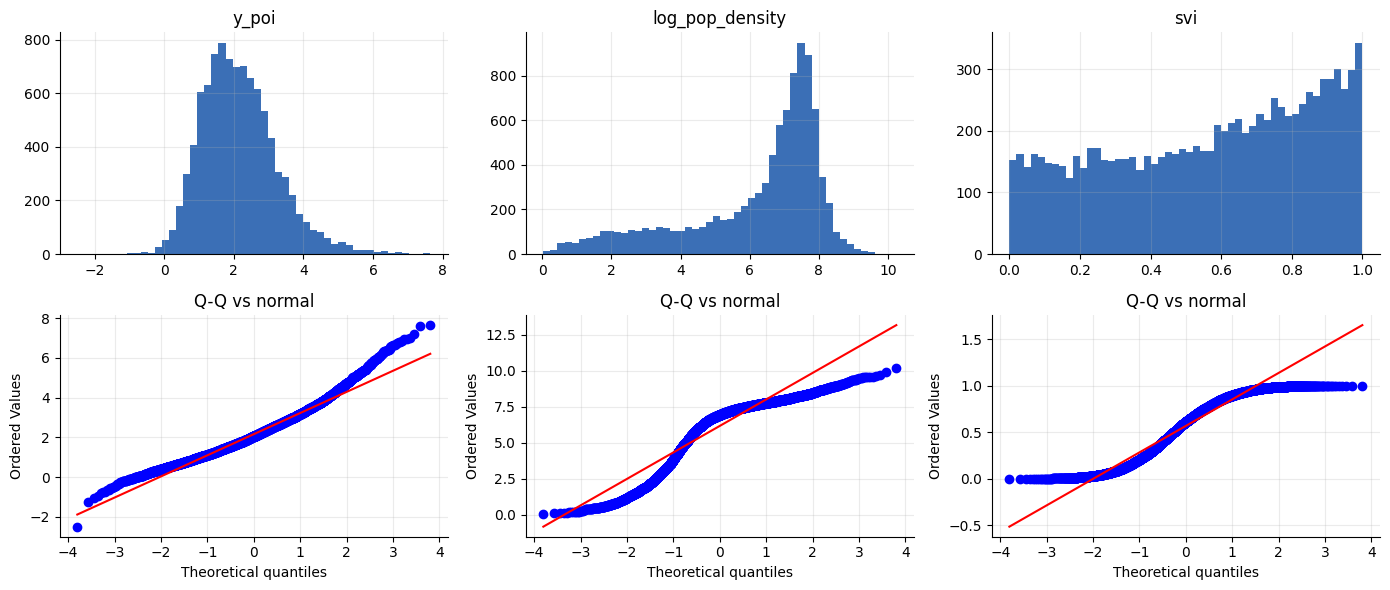

In [2]:
s = f[["y_poi", "tribal", "region", "ruca", "log_pop_density", "svi"]].dropna()
# normality of the outcome and of two predictors, before any transformation
rows = []
for c in ["y_poi", "log_pop_density", "svi"]:
    x = s[c].sample(5000, random_state=SEED)
    rows.append((c, stats.skew(s[c]), stats.kurtosis(s[c]), stats.shapiro(x).pvalue, stats.normaltest(s[c]).pvalue))
print(pd.DataFrame(rows, columns=["variable", "skew", "excess_kurtosis", "shapiro_p", "dagostino_p"]).round(4).to_string(index=False))
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for j, c in enumerate(["y_poi", "log_pop_density", "svi"]):
    ax[0, j].hist(s[c], bins=50, color="#3b6fb6"); ax[0, j].set_title(c)
    stats.probplot(s[c], plot=ax[1, j]); ax[1, j].set_title("Q-Q vs normal")
plt.tight_layout(); plt.show()

**Comment:** with ~10k tracts, formal normality tests reject almost anything, so we judge by skew and Q-Q shape. `y_poi` is only mildly right-skewed (skew 0.7), `log_pop_density` is left-skewed (-1.2) and `svi` is bounded and flat (negative kurtosis).

Welch t-test (parametric, means)                   9.93e-31
Mann-Whitney U (non-parametric, ranks)             2.70e-24
Levene (equal variance?)                           6.91e-08
ANOVA across regions (parametric)                  1.03e-49
Kruskal-Wallis across regions (non-parametric)     1.63e-43
Pearson y_poi~svi (linear)                         1.39e-59
Spearman y_poi~svi (rank)                          7.69e-90
Spearman y_poi~ruca (ordinal 1-10)                1.15e-227
Chi-square tribal x region                         0.00e+00


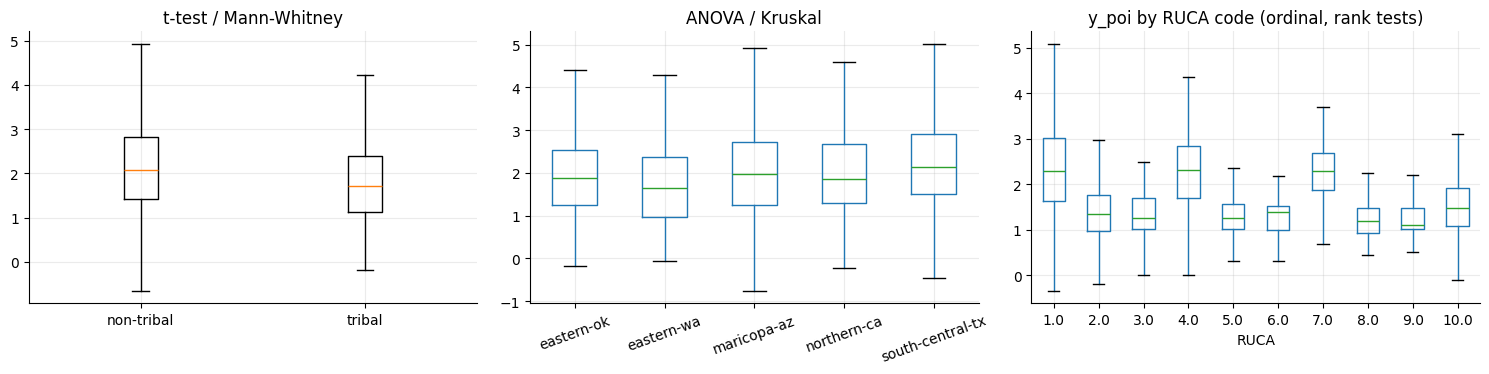

In [3]:
a, b = s[s.tribal == 1].y_poi, s[s.tribal == 0].y_poi
res = {
 "Welch t-test (parametric, means)": stats.ttest_ind(a, b, equal_var=False).pvalue,
 "Mann-Whitney U (non-parametric, ranks)": stats.mannwhitneyu(a, b).pvalue,
 "Levene (equal variance?)": stats.levene(a, b).pvalue,
 "ANOVA across regions (parametric)": stats.f_oneway(*[g.y_poi for _, g in s.groupby("region")]).pvalue,
 "Kruskal-Wallis across regions (non-parametric)": stats.kruskal(*[g.y_poi for _, g in s.groupby("region")]).pvalue,
 "Pearson y_poi~svi (linear)": stats.pearsonr(s.svi, s.y_poi)[1],
 "Spearman y_poi~svi (rank)": stats.spearmanr(s.svi, s.y_poi)[1],
 "Spearman y_poi~ruca (ordinal 1-10)": stats.spearmanr(s.ruca, s.y_poi)[1],
 "Chi-square tribal x region": stats.chi2_contingency(pd.crosstab(s.tribal, s.region))[1],
}
t = pd.Series(res, name="p-value")
print(t.map(lambda v: f"{v:.2e}").to_string())
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].boxplot([b, a], labels=["non-tribal", "tribal"], showfliers=False); ax[0].set_title("t-test / Mann-Whitney")
s.boxplot(column="y_poi", by="region", ax=ax[1], showfliers=False, rot=20); ax[1].set_title("ANOVA / Kruskal"); ax[1].set_xlabel(""); plt.suptitle("")
s.boxplot(column="y_poi", by="ruca", ax=ax[2], showfliers=False); ax[2].set_title("y_poi by RUCA code (ordinal, rank tests)"); ax[2].set_xlabel("RUCA"); plt.suptitle("")
plt.tight_layout(); plt.show()

**Comment:** parametric and rank tests agree on significance here (all p far below 0.001). Use rank tests (Mann-Whitney, Kruskal, Spearman) for ordinal codes like RUCA and for skewed counts; use Welch rather than Student when variances differ (Levene).

## 2 · Missingness, cleaning and imputation

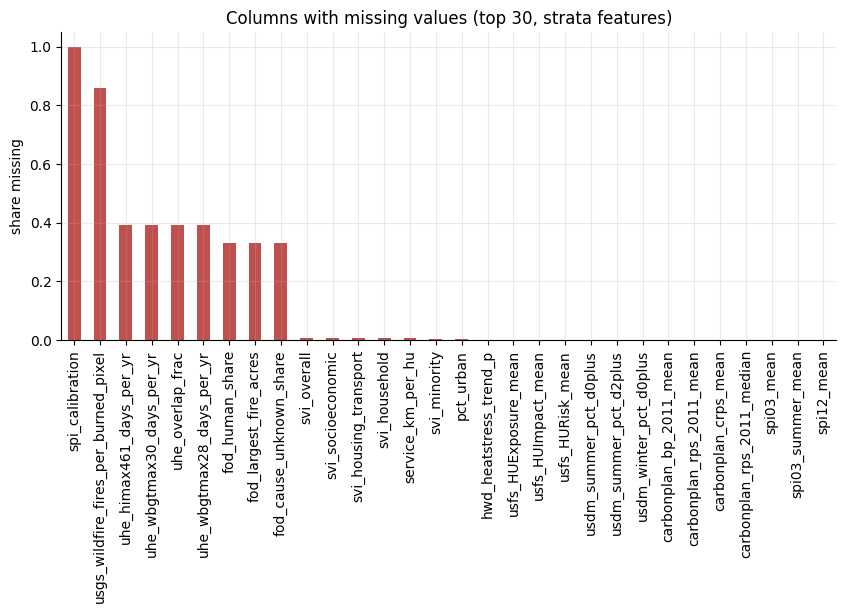

60 of 180 candidate columns have nulls; 2 are >50% null


In [4]:
d = pd.read_parquet(OUT / "tract_analysis_table.parquet")
num = d.select_dtypes(include=["number", "bool"]).copy()
num = num.drop(columns=[c for c in num.columns if any(k in c for k in ("Count", "bldg_", "poi_", "ratio_", "share_", "road_", "ru_", "rail", "infra", "carbonplan_buildings", "housing_units", "_year", "year_"))])
miss = num.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 4)); miss[miss > 0].head(30).plot.bar(ax=ax, color="#c0504d")
ax.set_ylabel("share missing"); ax.set_title("Columns with missing values (top 30, strata features)"); plt.show()
print(f"{(miss > 0).sum()} of {num.shape[1]} candidate columns have nulls; {(miss > .5).sum()} are >50% null")

**Comment:** most nulls are *structural* (never-burned tracts have no fire year; non-urban-heat cities have no UHE value), not random. Those should become an explicit flag / zero, not a mean.

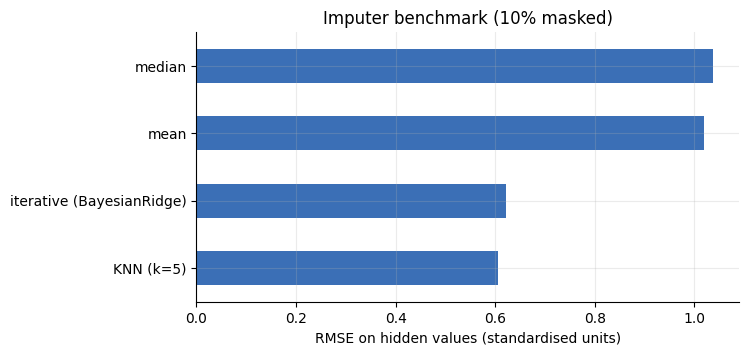

KNN (k=5)                    0.607
iterative (BayesianRidge)    0.623
mean                         1.019
median                       1.038


In [5]:
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler
# Benchmark: hide 10% of known values of a few real columns and see which imputer recovers them best.
cols = ["svi_overall", "svi_socioeconomic", "svi_household", "svi_minority", "svi_housing_transport", "cvi_overall", "cvi_climate", "cvi_baseline",
        "pct_urban", "ruca_pop_density", "usfs_WHP_mean", "usdm_summer_dsci", "epht_heat_days_summer", "gehe_wbgt28_days_mean"]
base = d[cols].astype(float).dropna().sample(3000, random_state=SEED)
mask = rng.random(base.shape) < .10
Xm = base.mask(mask)
Z = StandardScaler().fit(base)
errs = {}
for name, imp in {"mean": SimpleImputer(strategy="mean"), "median": SimpleImputer(strategy="median"),
                  "KNN (k=5)": KNNImputer(n_neighbors=5), "iterative (BayesianRidge)": IterativeImputer(random_state=SEED, max_iter=10)}.items():
    filled = imp.fit_transform(Z.transform(Xm))
    errs[name] = rmse(filled[mask], Z.transform(base)[mask])
errs = pd.Series(errs).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.5)); errs.plot.barh(ax=ax, color="#3b6fb6"); ax.set_xlabel("RMSE on hidden values (standardised units)"); ax.set_title("Imputer benchmark (10% masked)")
plt.show(); print(errs.round(3).to_string())

**Comment:** KNN and iterative imputers (RMSE 0.61 / 0.62) recover masked values far better than mean/median (about 1.0, i.e. no better than guessing the average) because strata columns are strongly inter-correlated. For structural nulls keep an indicator column.

## 3 · Transformations

               raw  log1p  Yeo-Johnson  quantile->normal
pop_density   3.46  -1.18        -0.22             -0.24
poi_n         5.68  -0.18         0.01             -0.01
bldg_n        1.69  -1.44         0.06             -0.00
road_density  0.10  -0.82        -0.20             -0.00


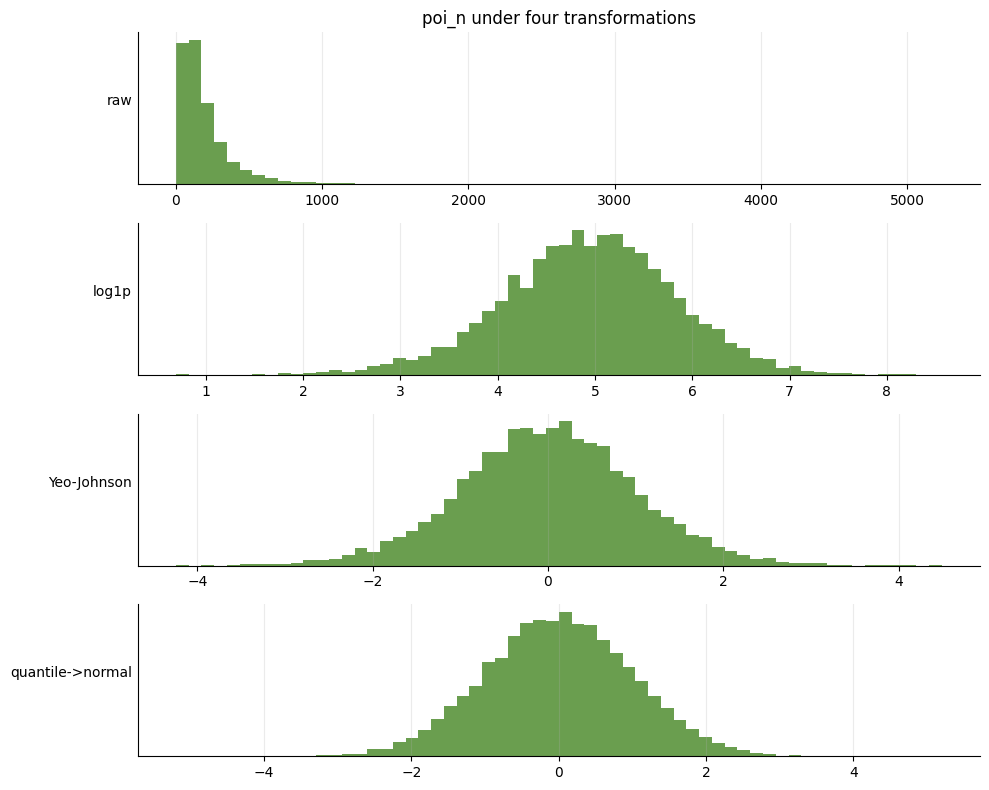

In [6]:
from sklearn.preprocessing import PowerTransformer, QuantileTransformer
raw = pd.DataFrame({"pop_density": f.pop_density, "poi_n": f.poi_n, "bldg_n": f.bldg_n, "road_density": np.expm1(f.log_road_density)}).dropna()
tr = {"raw": raw,
      "log1p": np.log1p(raw),
      "Yeo-Johnson": pd.DataFrame(PowerTransformer("yeo-johnson").fit_transform(raw), columns=raw.columns),
      "quantile->normal": pd.DataFrame(QuantileTransformer(output_distribution="normal", random_state=SEED).fit_transform(raw), columns=raw.columns)}
print(pd.DataFrame({k: v.apply(stats.skew) for k, v in tr.items()}).round(2).to_string())
fig, ax = plt.subplots(len(tr), 1, figsize=(10, 8), sharex=False)
for a_, (k, v) in zip(ax, tr.items()):
    a_.hist(v["poi_n"], bins=60, color="#6a9e4f"); a_.set_ylabel(k, rotation=0, ha="right"); a_.set_yticks([])
ax[0].set_title("poi_n under four transformations"); plt.tight_layout(); plt.show()

**Comment:** raw `poi_n` (skew 5.7) and `pop_density` (3.5) are heavily right-skewed. `log1p` fixes the right tail but can over-correct (pop_density goes to -1.2); Yeo-Johnson and quantile transforms land near 0. Linear models and distance-based methods benefit; trees do not care.

## 4 · Feature selection

candidate features: 178


after variance filter 147, after |r|>0.95 filter 116


LASSO keeps 96 of 116 features (alpha=0.0010)


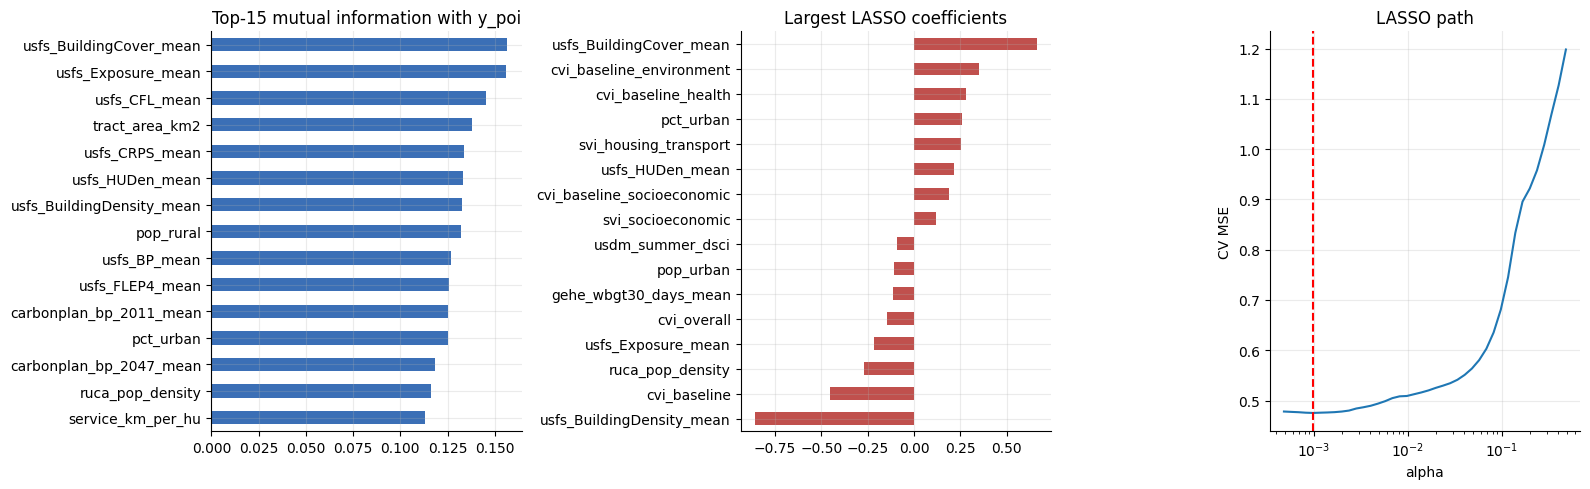

In [7]:
from sklearn.feature_selection import VarianceThreshold, mutual_info_regression
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
wide = num.loc[:, num.isna().mean() < .5].astype(float)
wide = wide.drop(columns=[c for c in wide.columns if c.startswith(("STATEFP", "COUNTYFP", "INTPT"))], errors="ignore")
wide["y_poi"] = f.y_poi.values
wide = wide.dropna(subset=["y_poi"]); wide = wide.replace([np.inf, -np.inf], np.nan)
y = wide.pop("y_poi")
Xw = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(wide), columns=wide.columns, index=wide.index)
print("candidate features:", Xw.shape[1])
# 1) variance filter
vt = VarianceThreshold(1e-6).fit(Xw); Xv = Xw.loc[:, vt.get_support()]
# 2) correlation filter: drop one of every pair with |rho| > 0.95
cm = Xv.corr().abs(); up = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool))
drop = [c for c in up.columns if (up[c] > .95).any()]; Xc = Xv.drop(columns=drop)
print(f"after variance filter {Xv.shape[1]}, after |r|>0.95 filter {Xc.shape[1]}")
# 3) mutual information  4) LASSO
mi = pd.Series(mutual_info_regression(Xc, y, random_state=SEED), Xc.columns).sort_values(ascending=False)
Xs = (Xc - Xc.mean()) / Xc.std()
lasso = LassoCV(cv=5, random_state=SEED, alphas=40).fit(Xs, y)
lc = pd.Series(lasso.coef_, Xc.columns)
sel = lc[lc != 0].index.tolist()
print(f"LASSO keeps {len(sel)} of {Xc.shape[1]} features (alpha={lasso.alpha_:.4f})")
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
mi.head(15)[::-1].plot.barh(ax=ax[0], color="#3b6fb6"); ax[0].set_title("Top-15 mutual information with y_poi")
lc[lc != 0].sort_values().iloc[np.r_[0:8, -8:0]].plot.barh(ax=ax[1], color="#c0504d"); ax[1].set_title("Largest LASSO coefficients")
ax[2].semilogx(lasso.alphas_, lasso.mse_path_.mean(axis=1)); ax[2].axvline(lasso.alpha_, color="r", ls="--"); ax[2].set(xlabel="alpha", ylabel="CV MSE", title="LASSO path")
plt.tight_layout(); plt.show()

**Comment:** the variance and correlation filters cut 178 columns to 116, but at its CV-optimal alpha LASSO keeps 96 of them, so most strata columns carry a little signal. Mutual information ranks features including non-linear signal; a stricter top-k cut is compared below.

## 5 · Case study: model before vs after preparation
Same ridge model, 5-fold CV, three recipes: (A) raw columns, median-filled, no transforms; (B) log-transformed skewed columns + KNN imputation; (C) B restricted to the LASSO-selected features.

                          R2    RMSE  R2 std
A raw + median        0.6233  0.6700  0.0176
B log + KNN impute    0.6355  0.6591  0.0187
C B + LASSO-selected  0.6311  0.6630  0.0170
D B + top-25 MI       0.5518  0.7308  0.0219 
(76 skewed columns log-transformed)


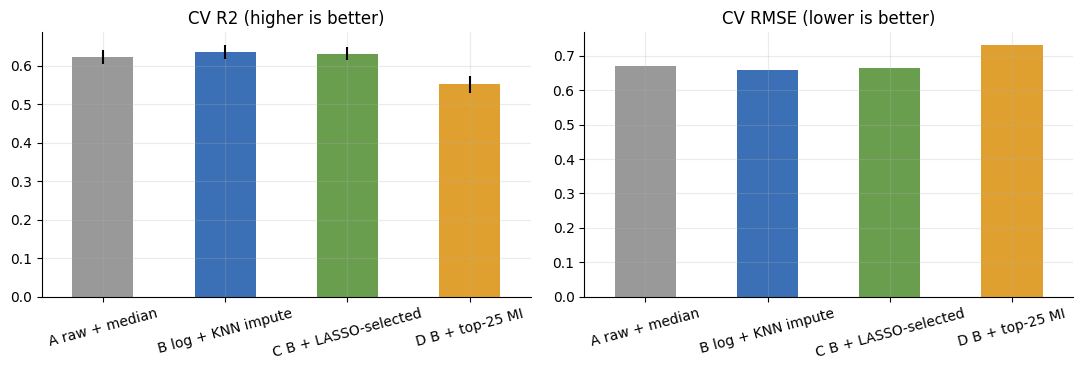

In [8]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import RidgeCV
cv = KFold(5, shuffle=True, random_state=SEED)
mk = lambda: RidgeCV(alphas=np.logspace(-2, 3, 15))
Xraw = Xw.copy()
skewed = [c for c in Xw.columns if Xw[c].min() >= 0 and abs(stats.skew(Xw[c])) > 2]
Xlog = Xw.copy(); Xlog[skewed] = np.log1p(Xlog[skewed])
Xb = pd.DataFrame(KNNImputer(n_neighbors=5).fit_transform(wide.assign(**{c: np.log1p(wide[c]) for c in skewed})), columns=wide.columns, index=wide.index)
def score(X):
    pipe = make_pipeline(StandardScaler(), mk())
    r2 = cross_val_score(pipe, X, y, cv=cv, scoring="r2"); rm = -cross_val_score(pipe, X, y, cv=cv, scoring="neg_root_mean_squared_error")
    return r2.mean(), rm.mean(), r2.std()
out = pd.DataFrame({"A raw + median": score(Xraw), "B log + KNN impute": score(Xb), "C B + LASSO-selected": score(Xb[[c for c in sel if c in Xb.columns]]),
                   "D B + top-25 MI": score(Xb[[c for c in mi.index[:25] if c in Xb.columns]])},
                   index=["R2", "RMSE", "R2 std"]).T
print(out.round(4).to_string(), f"\n({len(skewed)} skewed columns log-transformed)")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
out.R2.plot.bar(ax=ax[0], yerr=out["R2 std"], color=["#999", "#3b6fb6", "#6a9e4f", "#e0a030"], rot=15); ax[0].set_title("CV R2 (higher is better)")
out.RMSE.plot.bar(ax=ax[1], color=["#999", "#3b6fb6", "#6a9e4f", "#e0a030"], rot=15); ax[1].set_title("CV RMSE (lower is better)")
plt.tight_layout(); plt.show()

**Comment:** log-transform plus KNN imputation lifts CV R2 slightly (0.623 to 0.636) and RMSE falls (0.670 to 0.659). The high R2 is driven by building-density strata (the outcome's denominator is building count), not by POI information. Keeping only the top-25 mutual-information features costs about 0.08 R2 (0.552), so compactness is not free here.